# Handwriting generation: LSTM + Gaussian mixture (MDN) head

**Task.** Given a character, generate its pen trajectory as a sequence of steps $(dx_t, dy_t, \text{pen}_t)$.

**Pipeline in this notebook**

1. Data: `delta_data_equal_length.pkl` $\to$ padded tensors with a start token (teacher forcing)
2. Model: LSTM, a mixture head ($5K$ numbers) and a pen head (3 numbers)
3. Loss: Gaussian-mixture NLL for $(dx, dy)$ + weighted cross entropy for the pen state
4. Training with ground-truth inputs, early stopping, gradient clipping, interruption recovery, and five-epoch previews
5. Generation: deterministic (top component mean) and sampled (with temperature)
6. Plots

**Data assumption.** `delta_data[writer][char]` is a list of arrays of shape $(T, 3)$ with columns $dx, dy, \text{pen}$. Pen states: $0$ = down, $1$ = up, $2$ = end of character.

In [77]:
import math
import copy
from pathlib import Path
import pickle
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## 1. Data

For one sample with targets $\mathbf{y}_0, \dots, \mathbf{y}_{T-1}$ (each $\mathbf{y}_t = (dx_t, dy_t, \text{pen}_t)$), the model input is shifted by one step:

$$
\text{input} = [\,(0,0,1),\ \mathbf{y}_0,\ \mathbf{y}_1,\ \dots,\ \mathbf{y}_{T-2}\,], \qquad
\text{target} = [\,\mathbf{y}_0,\ \mathbf{y}_1,\ \dots,\ \mathbf{y}_{T-1}\,]
$$

The first input $(0,0,1)$ is the **start token**. Generation must start with the same token.
Sequences are padded to the same length and a mask marks the real steps.
The artificial `(0,0,1)` token already stored at the start of a trajectory is removed from the targets and retained only as the first input. EOS remains a pen target; its coordinates are excluded from the density loss. Character IDs start at **1**.


In [78]:
# ----------------------------------------------------
# A. Load the data and split by writer
# ----------------------------------------------------

with open("delta_data_normalized_max.pkl", "rb") as f:
    delta_data = pickle.load(f)

train_data = {}
val_data = {}
test_data = {}

# 1. Collect all test writer IDs
test_writer_ids = []
for writer_id in delta_data:
    if writer_id.startswith("tst_"):
        test_writer_ids.append(writer_id)

test_writer_ids.sort()

# 2. Split the 20 test writers in half (10 for val, 10 for test)
val_writers = test_writer_ids[:10]
test_writers = test_writer_ids[10:]

# 3. Fill the dictionaries
for writer_id in delta_data:
    if writer_id.startswith("trn_"):
        train_data[writer_id] = delta_data[writer_id]
    elif writer_id in val_writers:
        val_data[writer_id] = delta_data[writer_id]
    elif writer_id in test_writers:
        test_data[writer_id] = delta_data[writer_id]

# 4. Count total samples in each set
def count_samples(dataset):
    total = 0
    for writer_id in dataset:
        for char in dataset[writer_id]:
            total += len(dataset[writer_id][char])
    return total

print(f"Training set:   {len(train_data)} writers | {count_samples(train_data)} samples")
print(f"Validation set: {len(val_data)} writers | {count_samples(val_data)} samples")
print(f"Test set:       {len(test_data)} writers | {count_samples(test_data)} samples")
# ----------------------------------------------------
# B. Character ids (one unique number per character)
# ----------------------------------------------------

all_chars = []
for writer_id in delta_data:
    for char in delta_data[writer_id]:
        if char not in all_chars:
            all_chars.append(char)

# Shared one-based IDs: 1 through num_chars.
char_to_id = {char: i for i, char in enumerate(all_chars, start=1)}

num_chars = len(all_chars)
print("Total unique characters:", num_chars)

Training set:   40 writers | 7760 samples
Validation set: 10 writers | 1940 samples
Test set:       10 writers | 1940 samples
Total unique characters: 97


In [79]:
# ----------------------------------------------------
# C. Build input / target lists
# ----------------------------------------------------

def build_dataset_lists(data_split):
    c_list = []
    X_list = []
    y_list = []

    for writer_id in data_split:
        for char in data_split[writer_id]:
            c_id = char_to_id[char]

            for rep in data_split[writer_id][char]:
                traj = np.array(rep, dtype=np.float32, copy=True)
                inp = np.concatenate([traj[:-1]], axis=0)
                tgt = traj[1:]

                c_list.append(c_id)
                X_list.append(inp)
                y_list.append(tgt)

    return c_list, X_list, y_list


# ----------------------------------------------------
# D. Pad to the same length and build the mask
# ----------------------------------------------------

def pad_sequences(X_list, y_list, max_len):
    n = len(X_list)

    X = np.zeros((n, max_len, 3), dtype=np.float32)
    Y = np.zeros((n, max_len, 3), dtype=np.float32)
    M = np.zeros((n, max_len), dtype=np.float32)

    for i in range(n):
        L = len(y_list[i])
        X[i, :L, :] = X_list[i]
        Y[i, :L, :] = y_list[i]
        M[i, :L] = 1.0

    return X, Y, M


c_train, X_train, y_train = build_dataset_lists(train_data)
c_val,   X_val,   y_val   = build_dataset_lists(val_data)
c_test,  X_test,  y_test  = build_dataset_lists(test_data)

max_len = 0
for seq in y_train + y_val + y_test:
    if len(seq) > max_len:
        max_len = len(seq)

print("samples train/val/test:", len(c_train), len(c_val), len(c_test))
print("longest sequence:", max_len)


def make_dataset(c_list, X_list, y_list):
    X, Y, M = pad_sequences(X_list, y_list, max_len)

    # tensor order: 0 = input, 1 = char id, 2 = target, 3 = mask
    dataset = TensorDataset(
        torch.tensor(X),
        torch.tensor(c_list, dtype=torch.long),
        torch.tensor(Y),
        torch.tensor(M)
    )
    return dataset


train_dataset = make_dataset(c_train, X_train, y_train)
val_dataset   = make_dataset(c_val,   X_val,   y_val)
test_dataset  = make_dataset(c_test,  X_test,  y_test)

samples train/val/test: 7760 1940 1940
longest sequence: 97


### Training statistics used by the loss

**Coordinate scale.** $s_d$ is the standard deviation of $dx$ and $dy$ over the real training motion steps (excluding padding and EOS). The loss divides the coordinate errors by it.

**Pen-class weights.** Pen state 0 is usually the most frequent, so the rare classes get larger weights:

$$
w_i = \left(\frac{\text{count}_{\max}}{\text{count}_i}\right)^{p}
$$

$p = 0.5$ gives the square-root weights, $p = 1$ gives the full inverse-frequency weights.

In [80]:
# ----------------------------------------------------
# E. Coordinate std (real steps only)
# ----------------------------------------------------

train_xy = train_dataset.tensors[2][:, :, :2]            # (N, T, 2)
train_mask = train_dataset.tensors[3].bool()             # (N, T)

motion_mask = train_mask & (train_dataset.tensors[2][..., 2] != 2)
valid_xy = train_xy[motion_mask]                          # (n_valid, 2)
# ----------------------------------------------------
# F. Pen-state class weights
# ----------------------------------------------------

WEIGHT_POWER = 1     # 0.5 = square-root weights, 1.0 = full inverse frequency

train_pen = train_dataset.tensors[2][:, :, 2].long()     # pen state
class_counts = torch.bincount(train_pen[train_mask], minlength=3).float()

pen_class_weights = (class_counts.max() / class_counts.clamp(min=1)) ** WEIGHT_POWER
pen_class_weights = pen_class_weights.to(device)

print("class counts :", class_counts)
print("class weights:", pen_class_weights)

class counts : tensor([450018.,  12352.,   7760.])
class weights: tensor([ 1.0000, 36.4328, 57.9920])


## 2. Model

Each character ID selects a learned vector from `nn.Embedding`. Set its size with `EMBEDDING_DIM` in the training hyperparameters. IDs remain `1..num_chars`, with row `0` reserved. The vector is repeated at every time step and concatenated with `(dx, dy, pen)`, giving `3 + EMBEDDING_DIM` input features.

At every step the LSTM turns this input into a hidden vector $\mathbf{h}_t$ (the memory of the strokes so far). Two linear heads read it:

$$
\mathbf{o}_t = W\,\mathbf{h}_t + \mathbf{b} \in \mathbb{R}^{5K}, \qquad
\mathbf{s}_t = W_p\,\mathbf{h}_t + \mathbf{b}_p \in \mathbb{R}^{3}
$$

The $5K$ numbers are split as $[\,a_1..a_K \mid \mu_{1x},\mu_{1y},\dots \mid \ell_{1x},\ell_{1y},\dots\,]$:

| slice | size | meaning | becomes |
|---|---|---|---|
| mixture logits $a_k$ | $K$ | how much each Gaussian is trusted | $\pi_k = \text{softmax}(a)_k$ |
| means $\mu_{k,d}$ | $2K$ | centre of each Gaussian | used as is |
| log-stds $\ell_{k,d}$ | $2K$ | spread of each Gaussian | $\sigma_{k,d} = e^{\ell_{k,d}}$ |

The LSTM keeps the past. The mixture only describes what could come next from that past.

*If your own model class has the same `forward(x, c, hidden)` signature and returns `(xy_mdn, pen_logits, hidden)`, use it instead of this one.*

In [81]:
class LSTMMDN(nn.Module):

    def __init__(self, num_chars, K=5, hidden_size=256, num_layers=2,
                 embedding_dim=16, dropout=0.2):
        super().__init__()

        self.num_chars = num_chars
        self.embedding_dim = embedding_dim
        # IDs are 1..num_chars; reserve row 0.
        self.char_embedding = nn.Embedding(
            num_chars + 1, embedding_dim, padding_idx=0
        )

        # Input per step: dx, dy, pen, and a learned character vector.
        self.lstm = nn.LSTM(
            input_size=3 + embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.mdn_head = nn.Linear(hidden_size, 6 * K)   # mixture parameters
        self.pen_head = nn.Linear(hidden_size, 3)       # pen-state logits

    def forward(self, x, c, hidden=None):
        # x: (B, T, 3), c: (B,) character ids

        # Select one learned vector per character and repeat it across time.
        char_ids = c.to(device=x.device, dtype=torch.long).reshape(-1)
        char_emb = self.char_embedding(char_ids)         # (B, E)
        char_emb = char_emb.unsqueeze(1).expand(-1, x.shape[1], -1)
        inp = torch.cat([x, char_emb], dim=-1)             # (B, T, 3 + E)
        h, hidden = self.lstm(inp, hidden)

        xy_mdn = self.mdn_head(h)                        # (B, T, 6K)
        pen_logits = self.pen_head(h)                    # (B, T, 3)

        return xy_mdn, pen_logits, hidden

## 3. Loss

**Coordinates (mixture NLL).** With $z_{k,d} = \dfrac{y_d - \mu_{k,d}}{s_d\,\sigma_{k,d}}$ and independent $dx, dy$ inside each Gaussian:

$$
\log \mathcal{N}_k = -\tfrac12 \sum_{d} z_{k,d}^2 \;-\; \sum_d \ell_{k,d} \;-\; \log(2\pi)
$$

$$
\text{NLL} = -\log \sum_{k=1}^{K} \exp\!\big(\log \pi_k + \log \mathcal{N}_k\big)
$$

`logsumexp` and `log_softmax` keep this numerically stable. Dividing by $s_d$ only shifts the NLL by the constant $\log s_x + \log s_y$, so the gradients are the same as for raw units. $\mu$ stays in raw units, $\sigma$ lives in standardized units.

**Pen state (weighted cross entropy).** With true class $y$ and class weights $w$:

$$
\ell_t = -\,w_{y}\,\log p_{t,y}
$$

**Total.** Coordinate NLL is averaged over motion points $N_{motion}$ (excluding EOS and padding). Pen CE is averaged over all valid pen targets $N$, including EOS:

$$
\mathcal{L} = \frac{1}{N_{motion}}\sum_t m_t\,\mathbf{1}[y_{t,pen}\ne 2]\,\text{NLL}_t \;+\; \lambda\,\frac{1}{N}\sum_t m_t\,\ell_t
$$

with $\lambda$ = `PEN_WEIGHT`.

In [82]:
def compute_loss_and_metrics(predictions, targets, mask, coord_std, pen_weight):
    xy_mdn, pen_logits, _ = predictions
    mask = mask.bool()
    pen_target = targets[..., 2].long()
    coord_mask = mask & (pen_target != 2)

    # A. Coordinate NLL: select motion targets BEFORE evaluating the density.
    # Padding and EOS cannot influence either coordinate loss or its gradients.
    if coord_mask.any():
        raw = xy_mdn[coord_mask]
        K = raw.shape[-1] // 6
        pi_logits, mu, log_sigma, rho_raw = torch.split(raw, [K, 2*K, 2*K, K], dim=-1)
        mu = mu.reshape(-1, K, 2)
        log_sigma = log_sigma.reshape(-1, K, 2).clamp(min=-5, max=3)
        rho = 0.7 * torch.tanh(rho_raw)          # keeps rho inside (-1, 1)
        z = (targets[..., :2][coord_mask].unsqueeze(1) - mu) / log_sigma.exp()
        zx, zy = z[..., 0], z[..., 1]
        one_minus_r2 = 1 - rho**2

        log_gaussian = (
          -(zx**2 + zy**2 - 2*rho*zx*zy) / (2*one_minus_r2)
    - log_sigma.sum(dim=-1)
    - 0.5*torch.log(one_minus_r2)
    - math.log(2*math.pi)
    )
        log_pi = F.log_softmax(pi_logits, dim=-1)
        coord_loss = -torch.logsumexp(log_pi + log_gaussian, dim=-1).mean()
    else:
        coord_loss = xy_mdn[coord_mask].sum()

    # B. Weighted CE per valid pen target, including EOS.
    if mask.any():
        weights = pen_class_weights.to(device=pen_logits.device, dtype=pen_logits.dtype)
        pen_loss = F.cross_entropy(
            pen_logits[mask], pen_target[mask], weight=weights, reduction="none"
        ).mean()
    else:
        pen_loss = pen_logits[mask].sum()

    loss = coord_loss + pen_weight * pen_loss
    return loss, coord_loss, pen_loss


## 4. Training setup

* Coordinate NLL can be negative because continuous densities can exceed 1.
* Gradients are clipped to total norm `GRAD_CLIP` before each optimizer update.
* Epoch coordinate and pen losses use their respective valid-point counts, so evaluation does not depend on batching.
* Training prints train and validation loss, EOS recall and pen-up recall. Previews show epoch 1 and every fifth epoch; set `PREVIEW_EVERY = 0` to disable them.
* Interrupting the training cell restores the best completed validation model and saves its state dictionary. If validation has not completed once, the initial weights are restored. No additional preview is started after interruption.
* The generation and plotting helper cells below are defined before the training cell. Run the notebook from the top after changing character IDs or rebuilding targets.
* **Inputs:** training, validation and test always use ground-truth inputs.


In [83]:


BATCH_SIZE = 128

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)
# ----------------------------------------------------
# Hyperparameters
# ----------------------------------------------------

K = 20                  # number of Gaussians
HIDDEN_SIZE = 128
NUM_LAYERS = 3
EMBEDDING_DIM = 32       # Learned character-vector size
LEARNING_RATE = 1e-3
PEN_WEIGHT = 1        # lambda; lower it if WEIGHT_POWER = 1.0
NUM_EPOCHS = 1000
PATIENCE = 15
CHECKPOINT_PATH = "lstm_mdn_best.pth"

GRAD_CLIP = 100.0
PREVIEW_EVERY = 5
PREVIEW_MAX_STEPS = max_len
PREVIEW_CHARACTERS = None  # All characters, or ['a', 'b', 'A', '2']
PREVIEW_SAMPLED = False   # False: top-component mean; True: sampled coordinates

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    coord_sum = pen_sum = 0
    n_motion = n_steps = n_correct = 0
    n_up = up_hit = n_eos = eos_hit = 0

    for X, c, y, mask in loader:
        X, c, y = X.to(device), c.to(device), y.to(device)
        mask = mask.to(device).bool()

        # cut off the extra padding
        length = int(mask.sum(dim=1).max())
        X, y, mask = X[:, :length], y[:, :length], mask[:, :length]

        with torch.set_grad_enabled(training):
            predictions = model(X, c)
            loss, coord_loss, pen_loss = compute_loss_and_metrics(
                predictions, y, mask, None, PEN_WEIGHT)

        if training:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()

        # statistics
        pred = predictions[1].argmax(dim=-1)[mask]
        true = y[..., 2].long()[mask]

        motion = (true != 2).sum().item()
        coord_sum += coord_loss.item() * motion
        pen_sum += pen_loss.item() * len(true)
        n_motion += motion
        n_steps += len(true)
        n_correct += (pred == true).sum().item()

        n_up += (true == 1).sum().item()
        up_hit += ((true == 1) & (pred == 1)).sum().item()
        n_eos += (true == 2).sum().item()
        eos_hit += ((true == 2) & (pred == 2)).sum().item()

    coord = coord_sum / max(n_motion, 1)
    pen = pen_sum / n_steps

    return {
        "loss": coord + PEN_WEIGHT * pen,
        "coord_loss": coord,
        "pen_loss": pen,
        "pen_acc": n_correct / n_steps,
        "pen_up_recall": up_hit / max(n_up, 1),
        "eos_recall": eos_hit / max(n_eos, 1),
    }



## 5. Generation

Generation is autoregressive: the model output at step $t$ becomes the input at step $t+1$. The first input is the start token $(0,0,1)$, as in training. The loop stops when the model predicts pen state 2 (end of character). `max_steps` is only a safety limit.

**Deterministic version.** Take the Gaussian with the largest $\pi_k$ and use its mean:

$$
k^* = \arg\max_k \pi_k, \qquad (dx, dy) = \boldsymbol{\mu}_{k^*}
$$

**Sampled version.** Pick a component, then draw from it. The temperature $\tau$ controls the randomness:

$$
k \sim \text{softmax}(a/\tau), \qquad
y_d = \mu_{k,d} + s_d\,\sqrt{\tau}\,\sigma_{k,d}\,\epsilon_d, \quad \epsilon_d \sim \mathcal{N}(0,1)
$$

$\tau = 1$ is the learned coordinate mixture (the pen state still uses argmax), $\tau < 1$ is more conservative, $\tau \to 0$ is the deterministic version.

**Pen-up boost.** Pen-up is rare and its timing varies between writers, so its probability is often below the pen-down probability at every single step. `pen_up_boost` multiplies only that probability before the argmax. Use $1.0$ (no boost) first, and raise it only if dots and crossbars are missing.

In [84]:
def get_outputs(model, x, c, hidden, pen_up_boost):
    # run the model for one step
    xy_mdn, pen_logits, hidden = model(x, c, hidden)

    raw = xy_mdn[0, 0]
    K = raw.shape[0] // 6

    pi_logits = raw[0:K]
    mu = raw[K:3*K].reshape(K, 2)
    sigma = raw[3*K:5*K].reshape(K, 2).clamp(-5, 3).exp()
    rho = 0.95 * torch.tanh(raw[5*K:6*K])

    # choose the pen state
    pen_probs = torch.softmax(pen_logits[0, 0], dim=0)
    pen_probs[1] = pen_probs[1] * pen_up_boost
    pen = pen_probs.argmax().item()

    return pi_logits, mu, sigma, rho, pen, hidden


def generate_trajectory(model, char_id, max_steps=500,
                        initial_input=(0.0, 0.0, 1.0), pen_up_boost=1.0):
    model.eval()
    device = next(model.parameters()).device

    c = torch.tensor([char_id], device=device)
    x = torch.tensor([[initial_input]], dtype=torch.float32, device=device)
    hidden = None
    trajectory = []

    with torch.no_grad():
        for step in range(max_steps):
            pi_logits, mu, sigma, rho, pen, hidden = get_outputs(
                model, x, c, hidden, pen_up_boost)

            if pen == 2:
                trajectory.append([0.0, 0.0, 2.0])
                break

            # take the mean of the most likely Gaussian
            k = pi_logits.argmax().item()
            dx = mu[k, 0].item()
            dy = mu[k, 1].item()

            trajectory.append([dx, dy, pen])
            x = torch.tensor([[[dx, dy, pen]]], dtype=torch.float32, device=device)

    return np.array(trajectory, dtype=np.float32)


def generate_sampled_trajectory(model, char_id, max_steps=500,
                                initial_input=(0.0, 0.0, 1.0), temperature=0.7,
                                pen_up_boost=1.0, seed=None):
    model.eval()
    device = next(model.parameters()).device

    generator = None
    if seed is not None:
        generator = torch.Generator(device=device)
        generator.manual_seed(seed)

    c = torch.tensor([char_id], device=device)
    x = torch.tensor([[initial_input]], dtype=torch.float32, device=device)
    hidden = None
    trajectory = []

    with torch.no_grad():
        for step in range(max_steps):
            pi_logits, mu, sigma, rho, pen, hidden = get_outputs(
                model, x, c, hidden, pen_up_boost)

            if pen == 2:
                trajectory.append([0.0, 0.0, 2.0])
                break

            # pick one Gaussian
            pi = torch.softmax(pi_logits / temperature, dim=0)
            k = torch.multinomial(pi, 1, generator=generator).item()

            # two random numbers
            e = torch.randn(2, device=device, generator=generator)

            # use rho to link dx and dy
            ex = e[0]
            ey = rho[k] * e[0] + torch.sqrt(1 - rho[k]**2) * e[1]

            dx = (mu[k, 0] + sigma[k, 0] * ex * temperature**0.5).item()
            dy = (mu[k, 1] + sigma[k, 1] * ey * temperature**0.5).item()

            trajectory.append([dx, dy, pen])
            x = torch.tensor([[[dx, dy, pen]]], dtype=torch.float32, device=device)

    return np.array(trajectory, dtype=np.float32)

## 6. From deltas to strokes and plots

Positions are the running sum of the deltas, starting at $(0,0)$:

$$
x_t = x_{t-1} + dx_t, \qquad y_t = y_{t-1} + dy_t
$$

A step is drawn when its pen state is $0$ (down). Pen state $1$ (up) is an air move, and pen state $2$ ends the character.

In [85]:
def deltas_to_strokes(trajectory):
    # pen_state = 0: pen is DOWN (draw this step)
    # pen_state = 1 or 2: pen is UP or end (do not draw, close the stroke)

    strokes = []
    current_stroke = []

    x, y = 0.0, 0.0

    for dx, dy, pen_state in trajectory:
        if pen_state == 2:
            break
        prev_x, prev_y = x, y
        x = x + dx
        y = y + dy

        if pen_state == 0:
            # first point of a stroke: include the "from" position too
            if not current_stroke:
                current_stroke.append((prev_x, prev_y))
            current_stroke.append((x, y))
        else:
            if current_stroke:
                strokes.append(current_stroke)
                current_stroke = []

    # save the last stroke if it exists
    if current_stroke:
        strokes.append(current_stroke)

    return strokes


def plot_strokes(trajectory, title=""):
    strokes = deltas_to_strokes(trajectory)

    for stroke in strokes:
        xs = []
        ys = []
        for point in stroke:
            xs.append(point[0])
            ys.append(point[1])
        plt.plot(xs, ys, marker=".", markersize=3)

    plt.gca().set_aspect("equal")
    plt.title(title)

In [86]:
# Live previews: generation helpers above are defined before training starts.
from IPython.display import display


def plot_training_samples(model, epoch, display_handle=None, best=False):
    characters = sorted(char_to_id) if PREVIEW_CHARACTERS is None else list(PREVIEW_CHARACTERS)
    if not characters:
        return display_handle
    ncols = min(8, len(characters))
    nrows = math.ceil(len(characters) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3*ncols, 3*nrows), squeeze=False)
    try:
        for ax, char in zip(axes.flat, characters):
            if char not in char_to_id:
                ax.set_title(f"{char!r}: unavailable")
                ax.axis("off")
                continue
            if PREVIEW_SAMPLED:
                trajectory = generate_sampled_trajectory(
                    model, char_to_id[char], max_steps=PREVIEW_MAX_STEPS,
                    seed=SEED + char_to_id[char],
                )
            else:
                trajectory = generate_trajectory(model, char_to_id[char], max_steps=140)
            strokes = deltas_to_strokes(trajectory)
            for stroke in strokes:
                xs, ys = zip(*stroke)
                ax.plot(xs, ys, "-o", markersize=2)
            if not strokes:
                ax.text(0.5, 0.5, "No drawing yet", ha="center", va="center", transform=ax.transAxes)
            ended = len(trajectory) > 0 and trajectory[-1, 2] == 2
            status = "EOS" if ended else "step limit"
            ax.set_title(f"{char!r}: {len(trajectory)} steps ({status})", fontsize=10)
            ax.set_aspect("equal")
            ax.grid(True, alpha=0.3)
        for ax in axes.flat[len(characters):]:
            ax.axis("off")
        label = "Best model" if best else "Current model"
        fig.suptitle(f"{label} — epoch {epoch}", fontsize=16)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        if display_handle is None:
            display_handle = display(fig, display_id=True)
        else:
            display_handle.update(fig)
        return display_handle
    finally:
        plt.close(fig)


## Run training
Run the following cell to train with ground-truth inputs. Use the notebook interrupt/stop control to stop and restore the best model.


Epoch 1 | train 2.0316 | val 0.8115 | EOS recall 0.000 | pen-up recall 0.625 | lr 1.0e-03


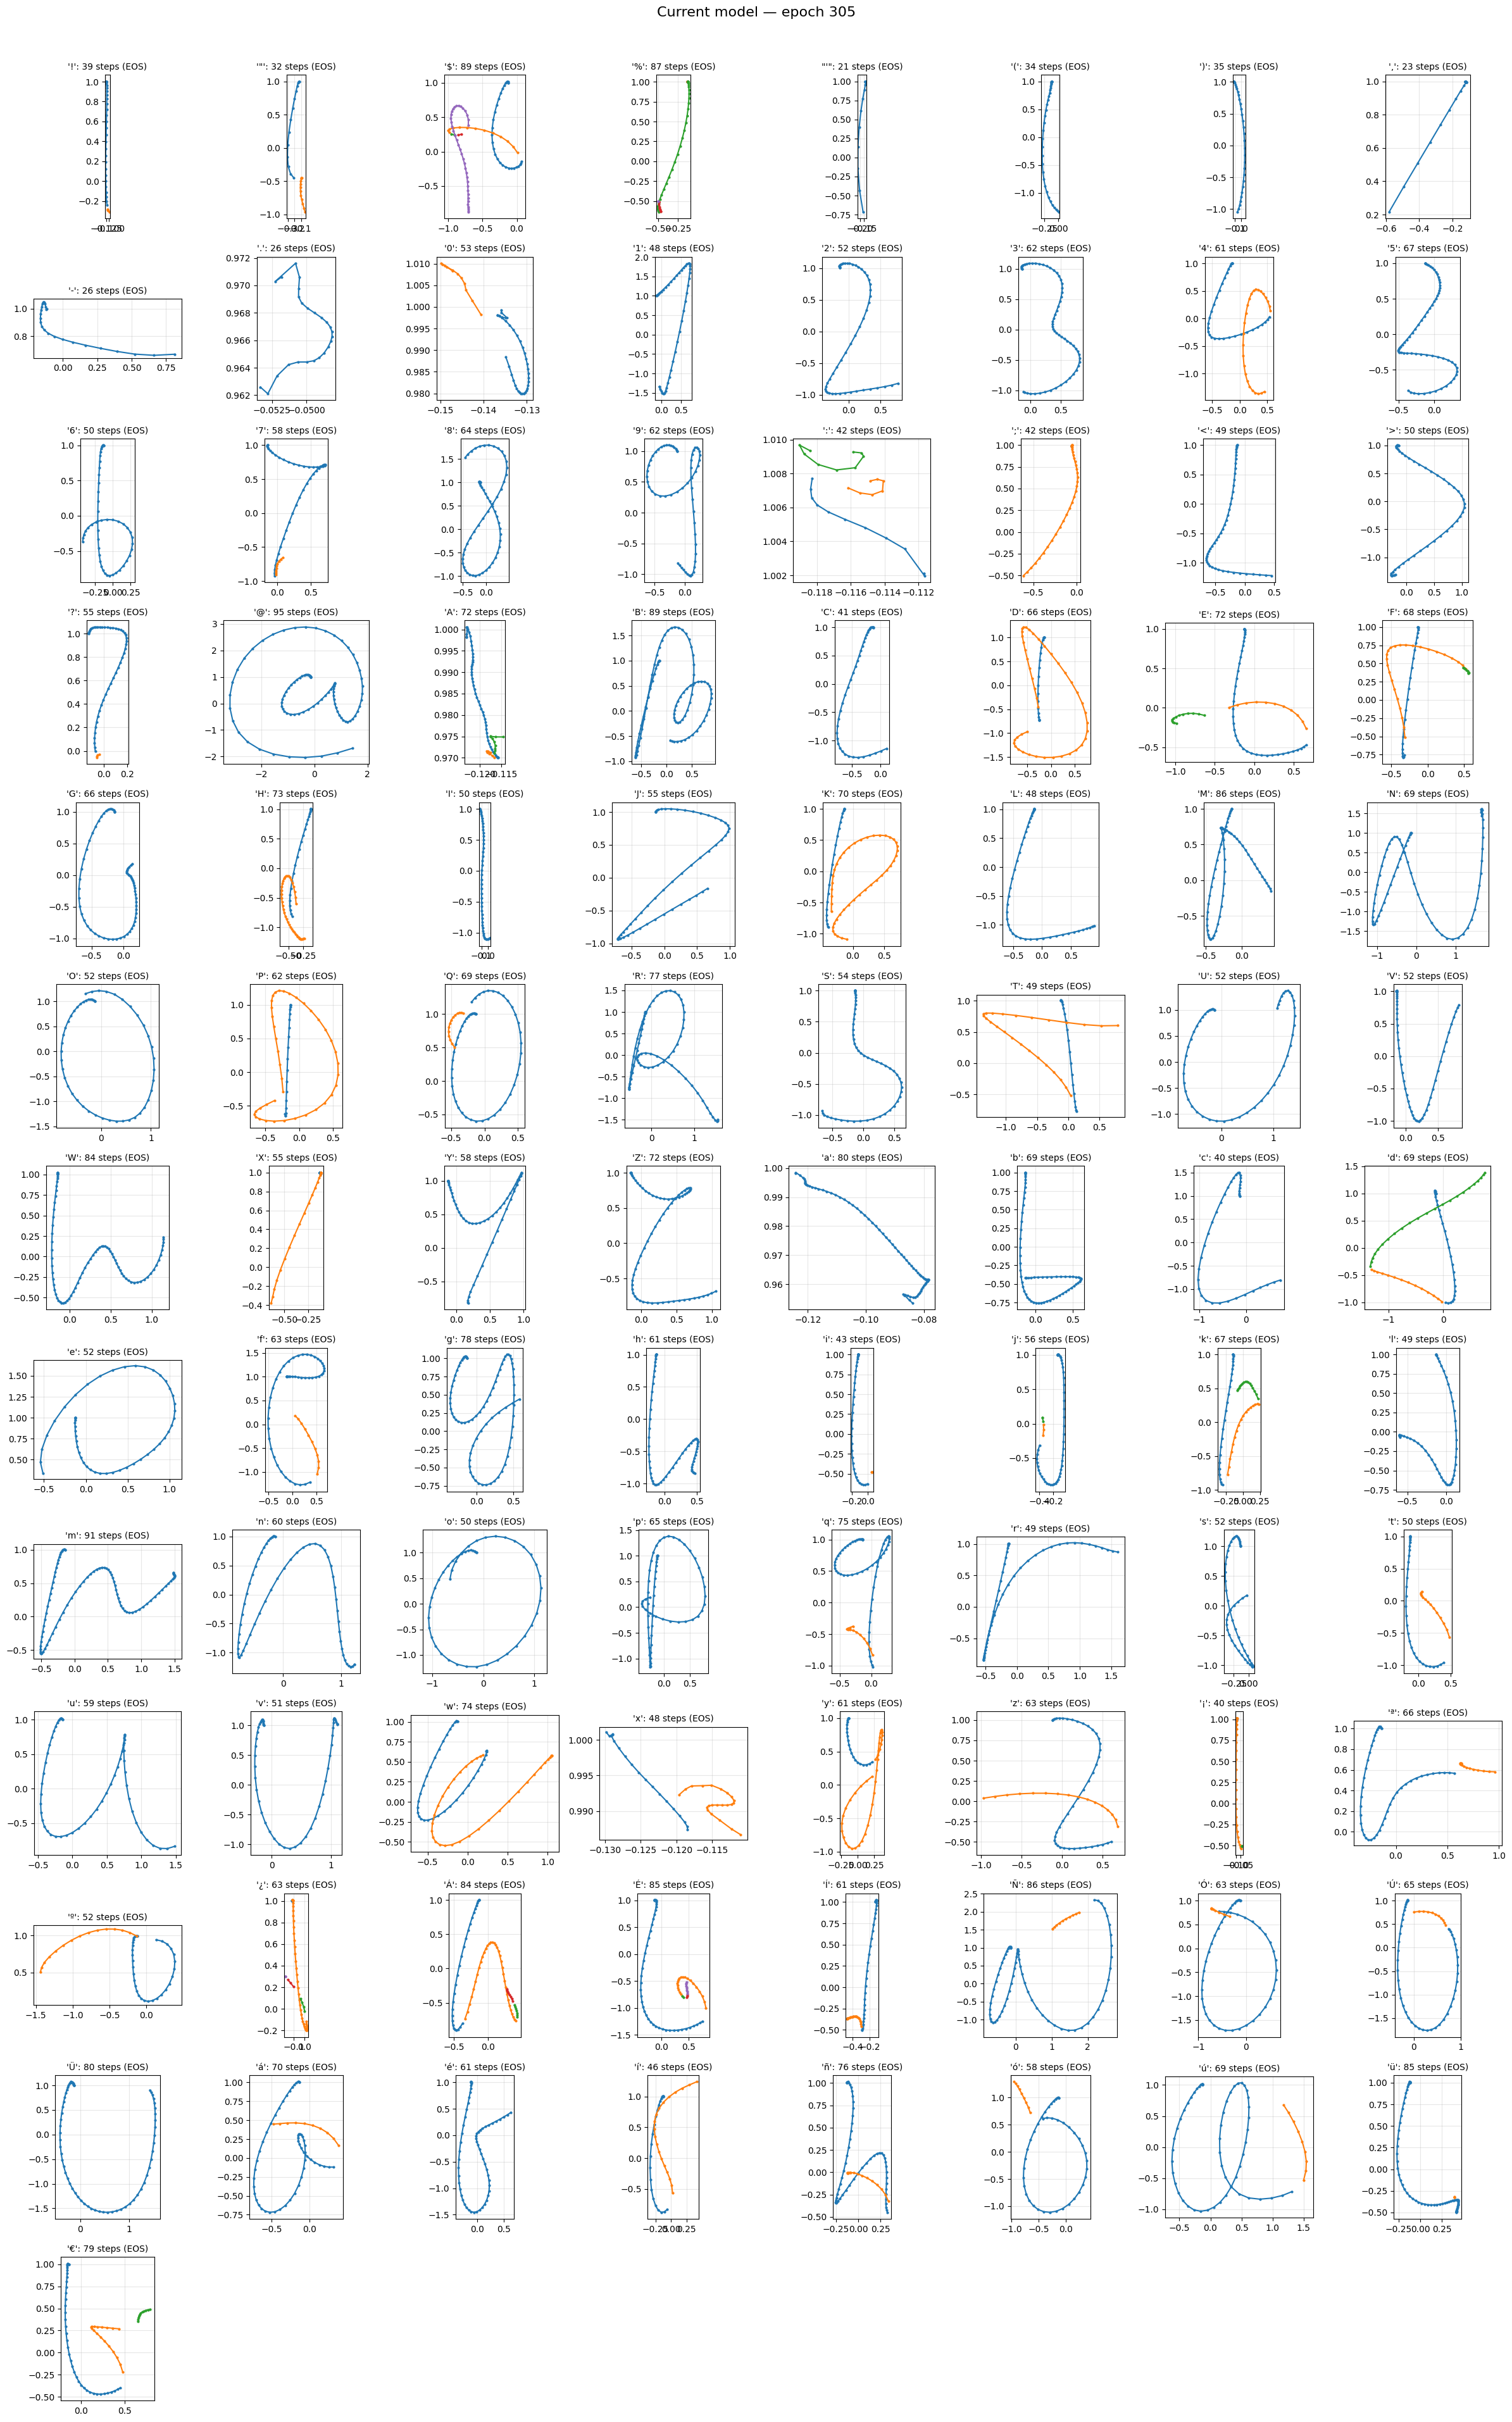

Epoch 2 | train 0.4703 | val 0.3144 | EOS recall 1.000 | pen-up recall 0.625 | lr 1.0e-03
Epoch 3 | train 0.2969 | val 0.2159 | EOS recall 0.711 | pen-up recall 0.625 | lr 1.0e-03
Epoch 4 | train 0.1473 | val 0.1120 | EOS recall 0.856 | pen-up recall 0.625 | lr 1.0e-03
Epoch 5 | train -0.0871 | val -0.2776 | EOS recall 0.835 | pen-up recall 0.625 | lr 1.0e-03
Epoch 6 | train -0.5487 | val -0.6640 | EOS recall 0.845 | pen-up recall 0.637 | lr 1.0e-03
Epoch 7 | train -0.7340 | val -0.8549 | EOS recall 0.990 | pen-up recall 0.688 | lr 1.0e-03
Epoch 8 | train -0.9518 | val -1.0818 | EOS recall 0.919 | pen-up recall 0.799 | lr 1.0e-03
Epoch 9 | train -1.1489 | val -1.3016 | EOS recall 0.956 | pen-up recall 0.794 | lr 1.0e-03
Epoch 10 | train -1.3322 | val -1.1953 | EOS recall 0.859 | pen-up recall 0.860 | lr 1.0e-03
Epoch 11 | train -1.3937 | val -1.3659 | EOS recall 0.951 | pen-up recall 0.877 | lr 1.0e-03
Epoch 12 | train -1.4739 | val -1.5466 | EOS recall 0.990 | pen-up recall 0.896 | lr

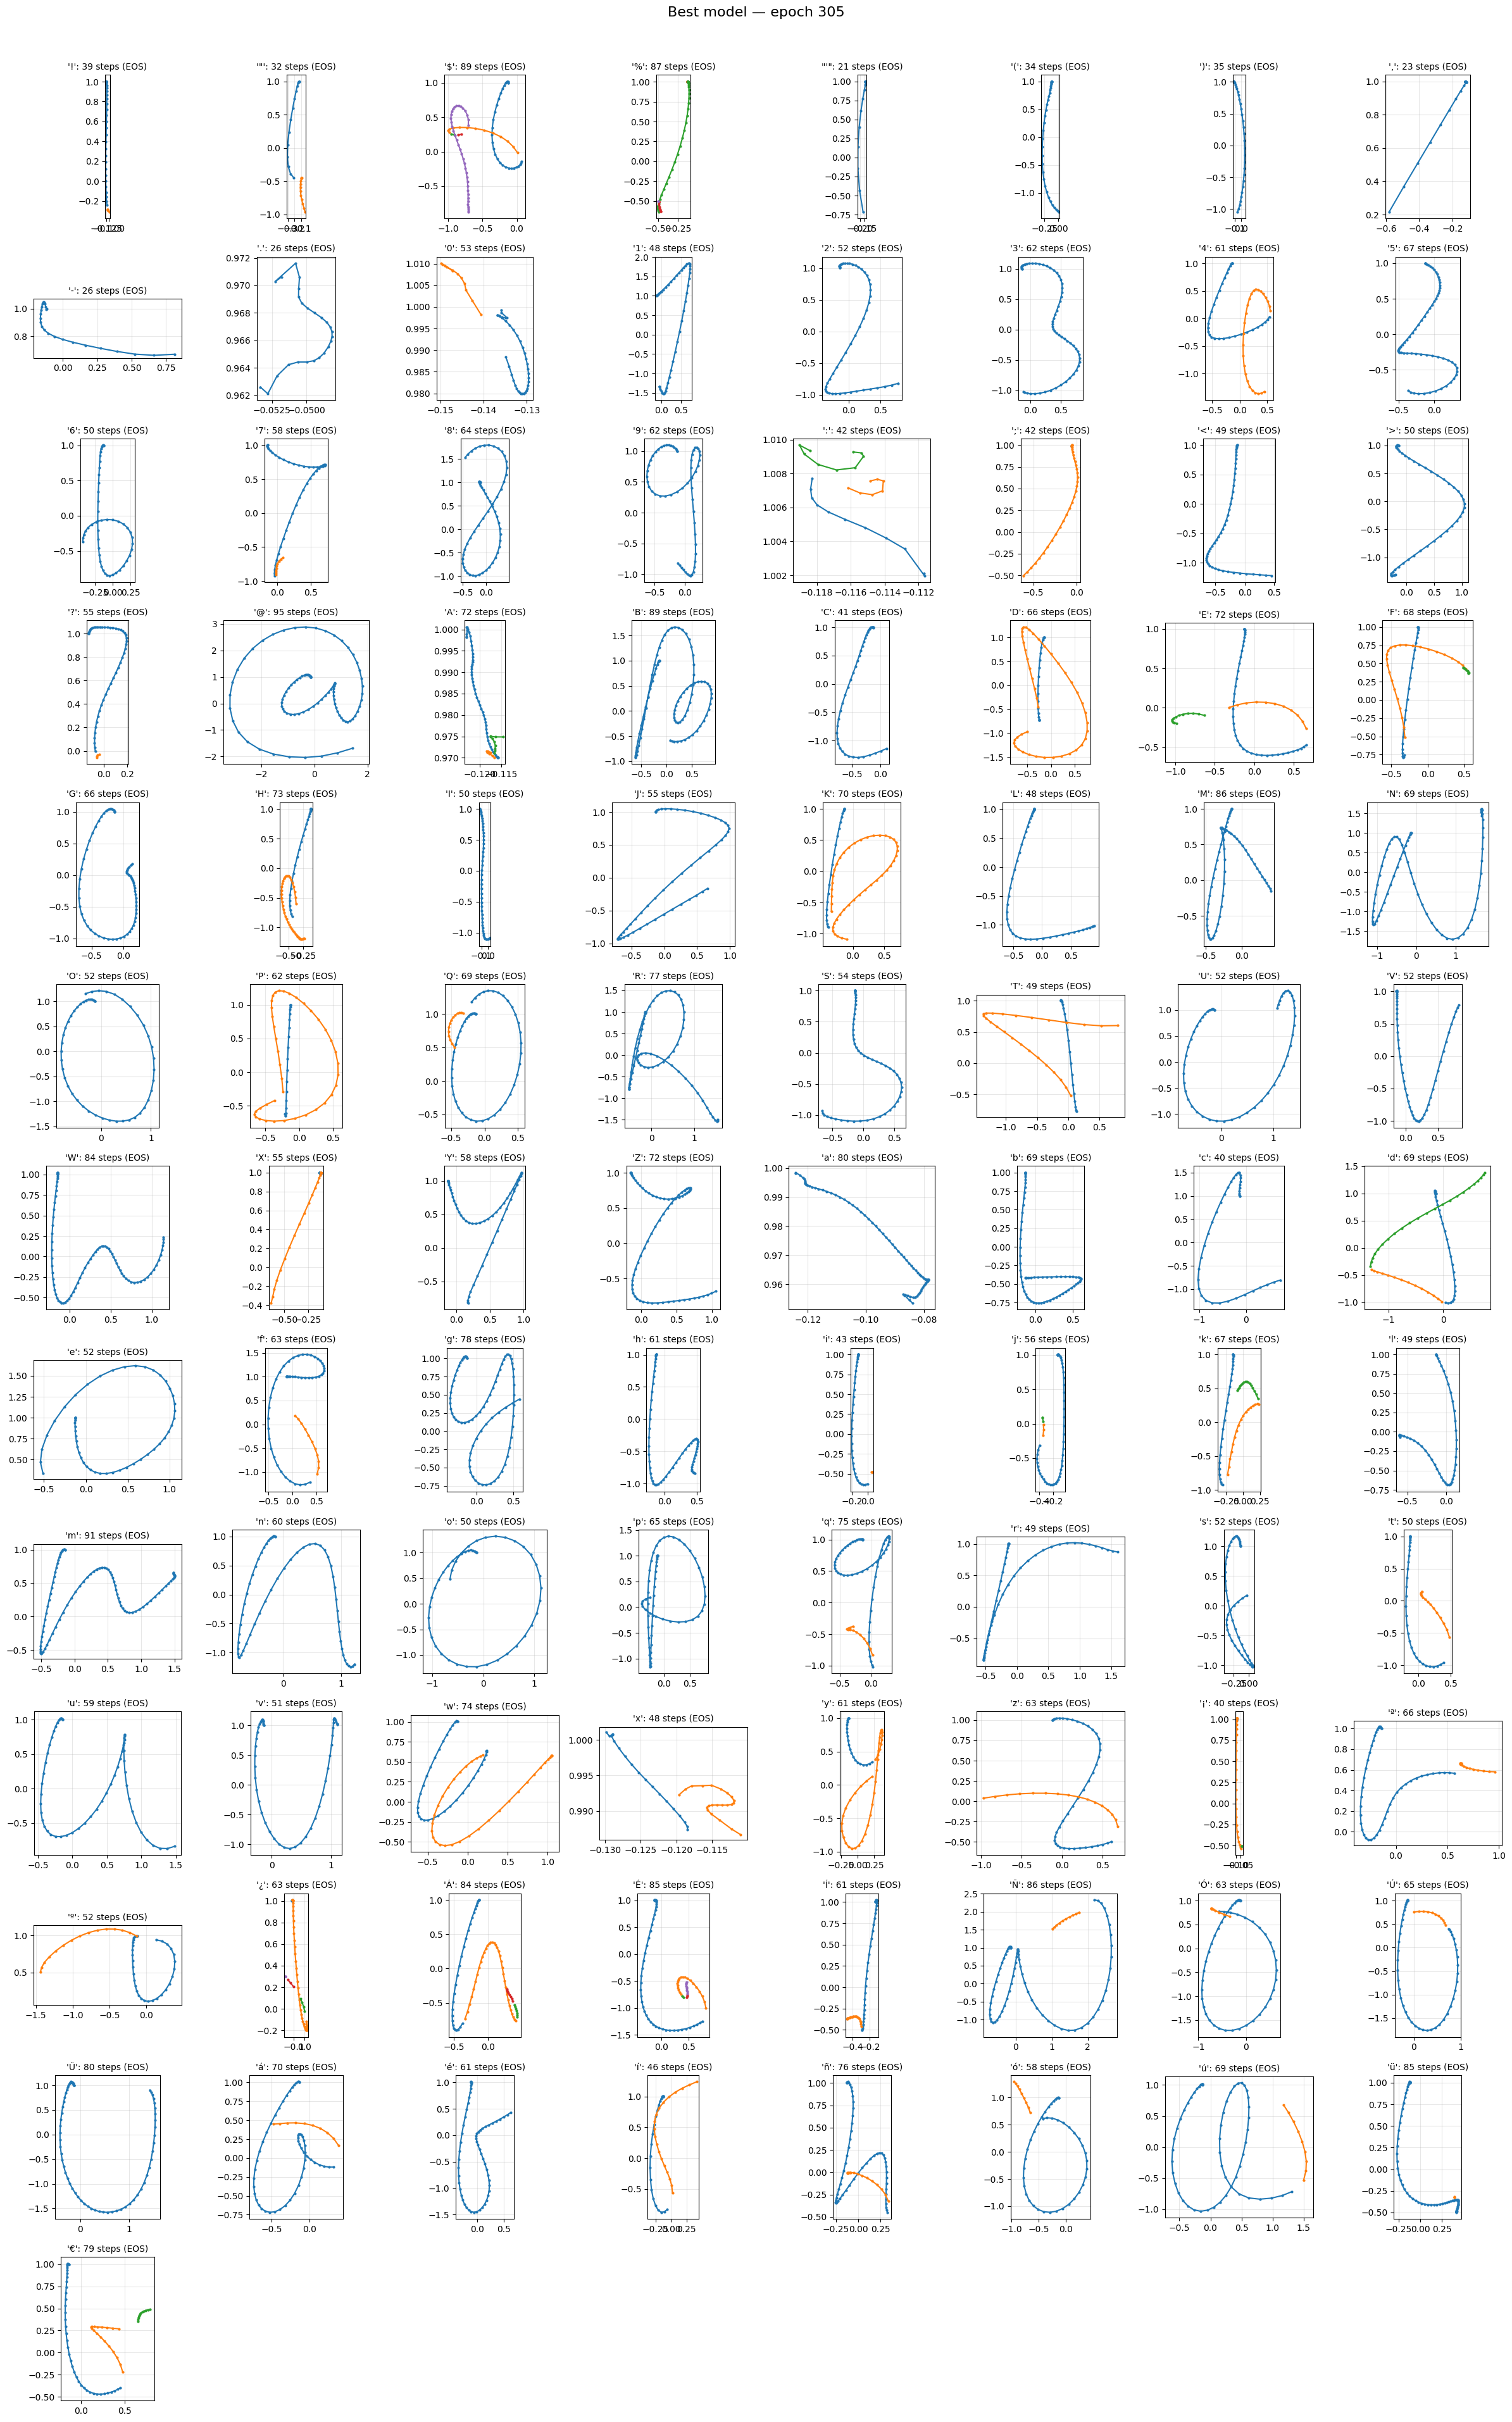

Epoch 311 | train -5.1896 | val -5.4413 | EOS recall 0.994 | pen-up recall 0.973 | lr 9.8e-07
Epoch 312 | train -5.1881 | val -5.4418 | EOS recall 0.995 | pen-up recall 0.973 | lr 9.8e-07
Epoch 313 | train -5.1891 | val -5.4412 | EOS recall 0.994 | pen-up recall 0.973 | lr 9.8e-07
Epoch 314 | train -5.1889 | val -5.4415 | EOS recall 0.994 | pen-up recall 0.973 | lr 9.8e-07
Epoch 315 | train -5.1920 | val -5.4418 | EOS recall 0.995 | pen-up recall 0.973 | lr 9.8e-07
Epoch 316 | train -5.1889 | val -5.4416 | EOS recall 0.994 | pen-up recall 0.973 | lr 9.8e-07
Epoch 317 | train -5.1902 | val -5.4416 | EOS recall 0.995 | pen-up recall 0.973 | lr 9.8e-07
Epoch 318 | train -5.1882 | val -5.4423 | EOS recall 0.995 | pen-up recall 0.973 | lr 9.8e-07
Epoch 319 | train -5.1928 | val -5.4419 | EOS recall 0.995 | pen-up recall 0.973 | lr 9.8e-07
Epoch 320 | train -5.1906 | val -5.4424 | EOS recall 0.995 | pen-up recall 0.973 | lr 9.8e-07
Early stopping.
Best epoch: 305 | best val loss: -5.4426


In [87]:
model = LSTMMDN(num_chars, K=K, hidden_size=HIDDEN_SIZE,
                num_layers=NUM_LAYERS, embedding_dim=EMBEDDING_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0
best_state = copy.deepcopy(model.state_dict())
wait = 0                     # epochs without improvement
preview = None

try:
    for epoch in range(1, NUM_EPOCHS + 1):
        train = run_epoch(model, train_loader, optimizer)
        val = run_epoch(model, val_loader)
        scheduler.step(val["loss"])

        train_losses.append(train["loss"])
        val_losses.append(val["loss"])

        # keep the best model
        if val["loss"] < best_val_loss:
            best_val_loss = val["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, CHECKPOINT_PATH)
            wait = 0
        else:
            wait += 1

        print(f"Epoch {epoch} | "
              f"train {train['loss']:.4f} | val {val['loss']:.4f} | "
              f"EOS recall {val['eos_recall']:.3f} | "
              f"pen-up recall {val['pen_up_recall']:.3f} | "
              f"lr {optimizer.param_groups[0]['lr']:.1e}")

        if PREVIEW_EVERY > 0 and (epoch == 1 or epoch % PREVIEW_EVERY == 0):
            preview = plot_training_samples(model, epoch, preview)

        # early stopping
        if wait >= PATIENCE:
            print("Early stopping.")
            break

except KeyboardInterrupt:
    print("Training stopped by user.")

# load the best model
model.load_state_dict(best_state)
model.eval()
print(f"Best epoch: {best_epoch} | best val loss: {best_val_loss:.4f}")

if PREVIEW_EVERY > 0 and best_epoch > 0:
    plot_training_samples(model, best_epoch, preview, best=True)

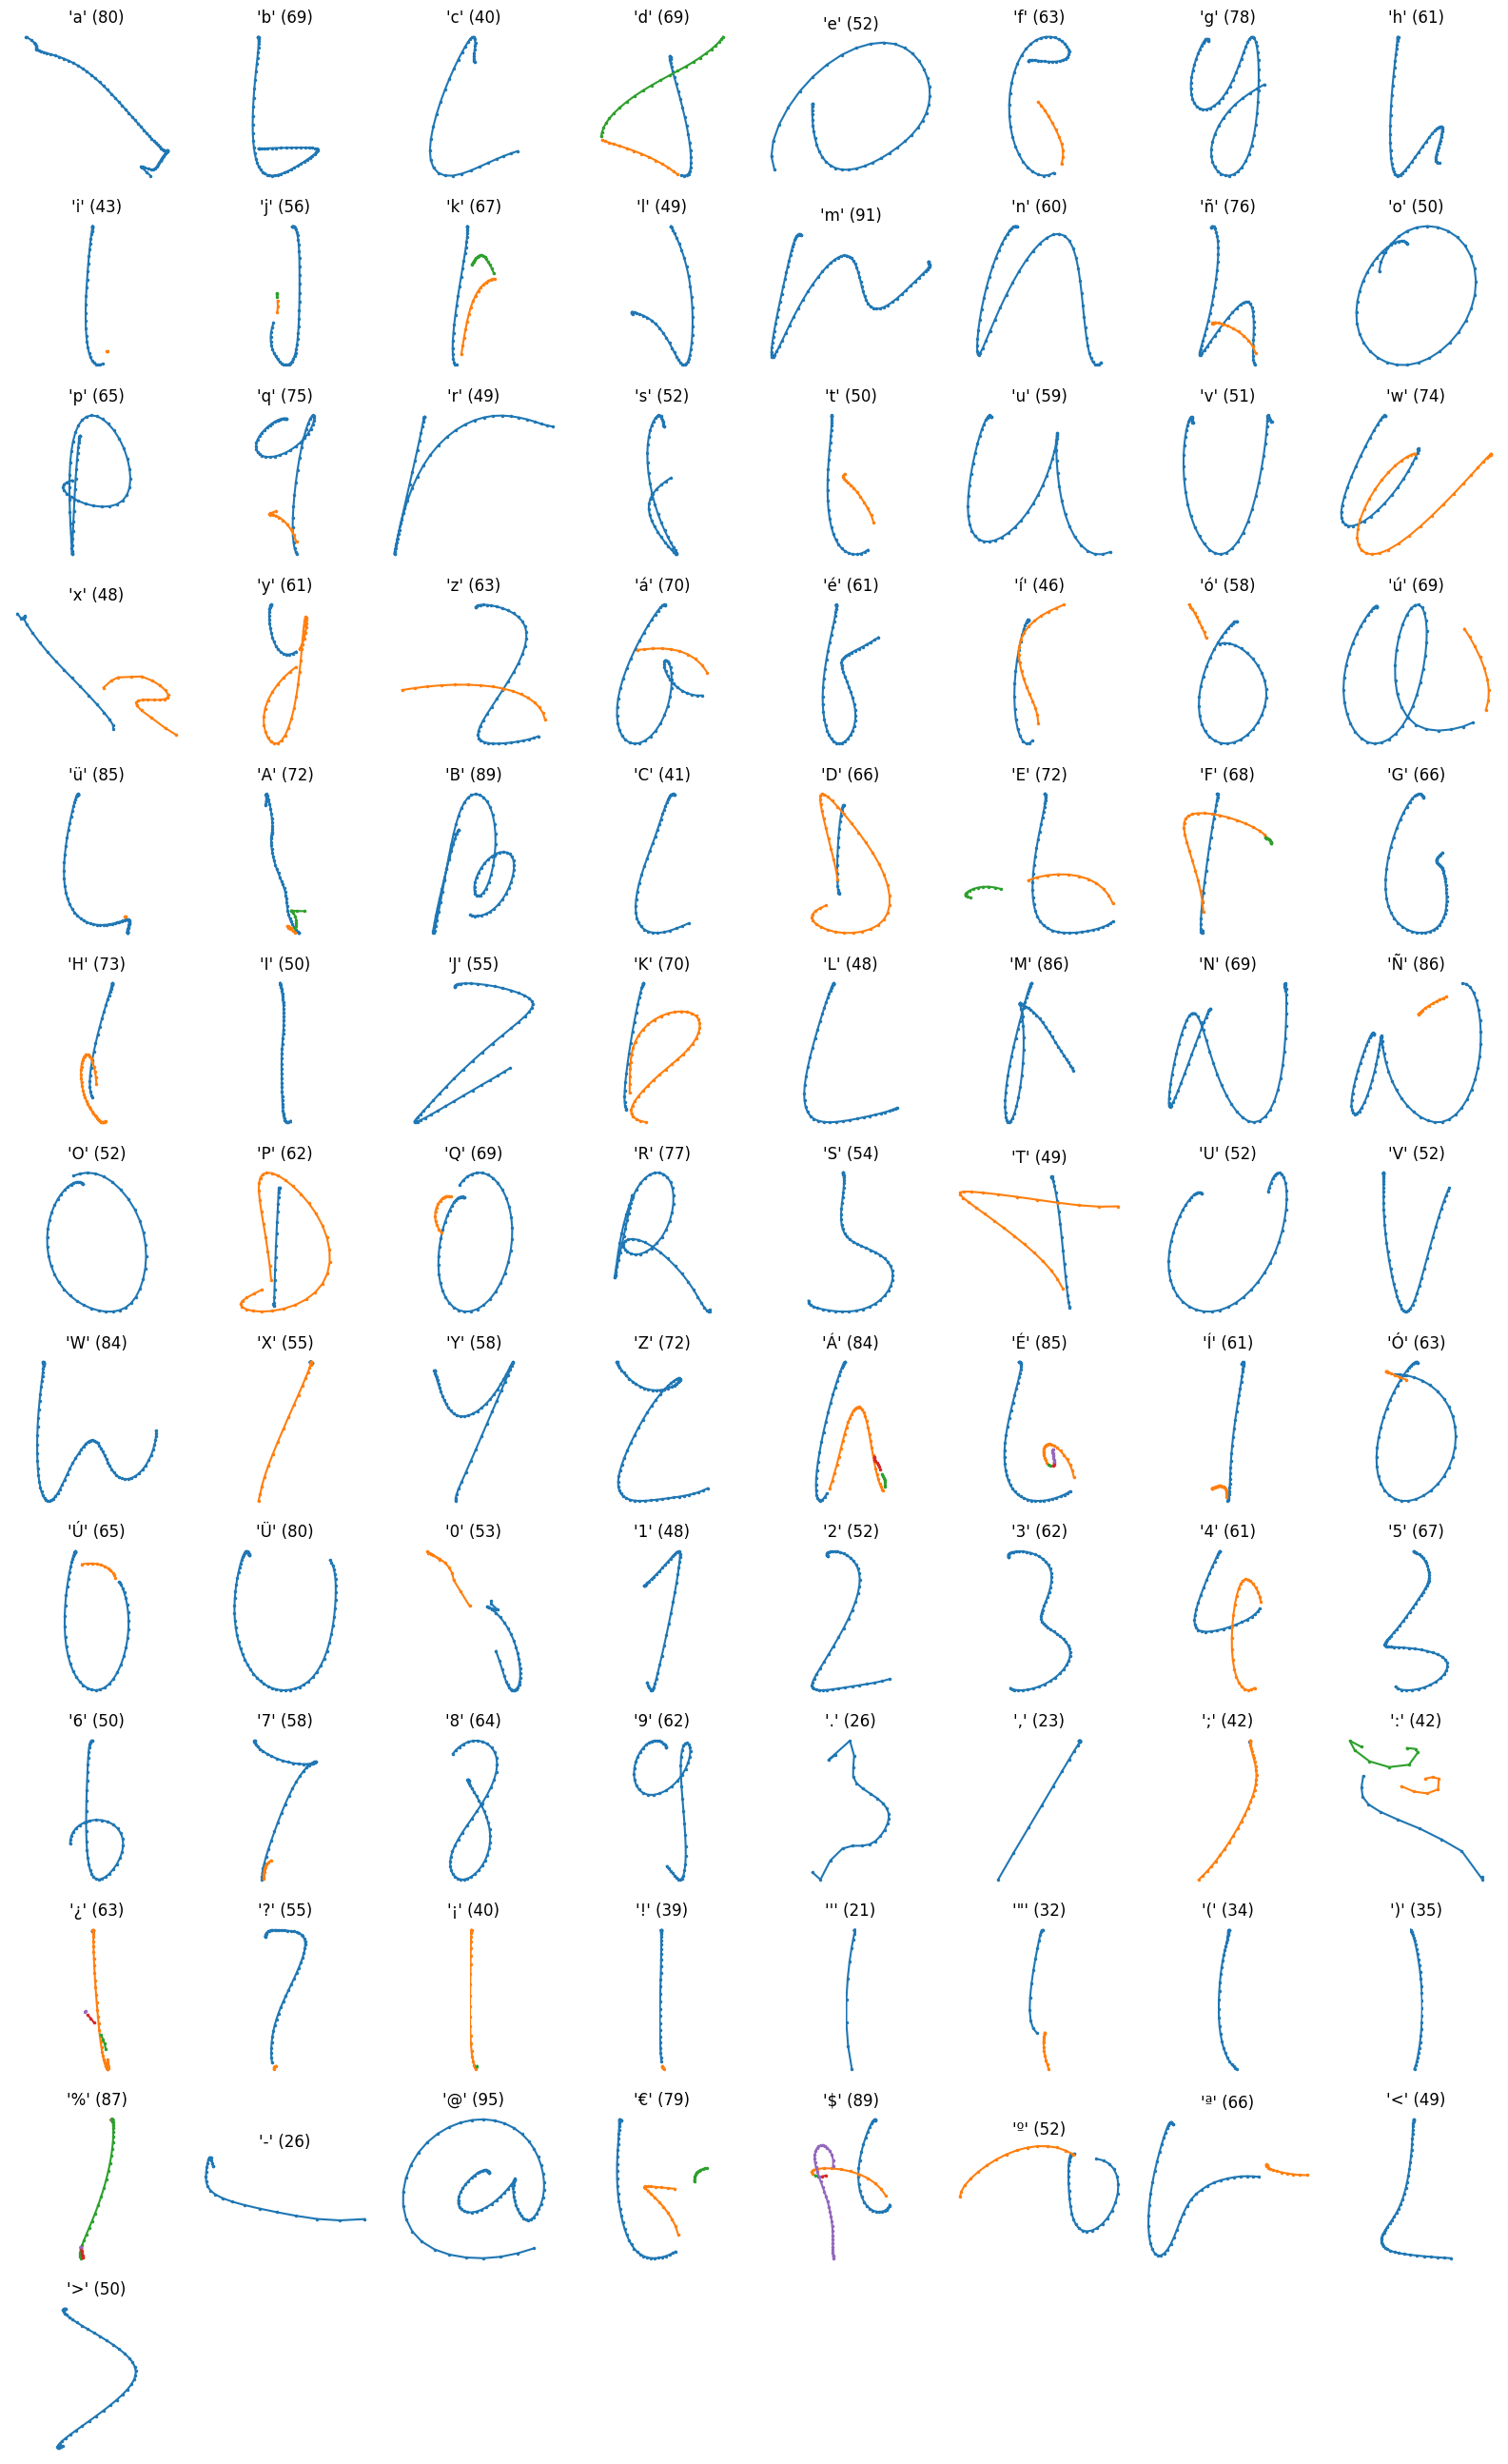

In [88]:
# ----------------------------------------------------
# All characters (deterministic), title = generated length
# ----------------------------------------------------

ncols = 8
nrows = math.ceil(num_chars / ncols)

plt.figure(figsize=(2 * ncols, 2 * nrows))

for i in range(num_chars):
    ch = all_chars[i]
    traj = generate_trajectory(model, char_to_id[ch], max_steps=max_len)

    plt.subplot(nrows, ncols, i + 1)
    plot_strokes(traj, "'" + ch + "' (" + str(len(traj)) + ")")
    plt.axis("off")

plt.tight_layout()
plt.show()

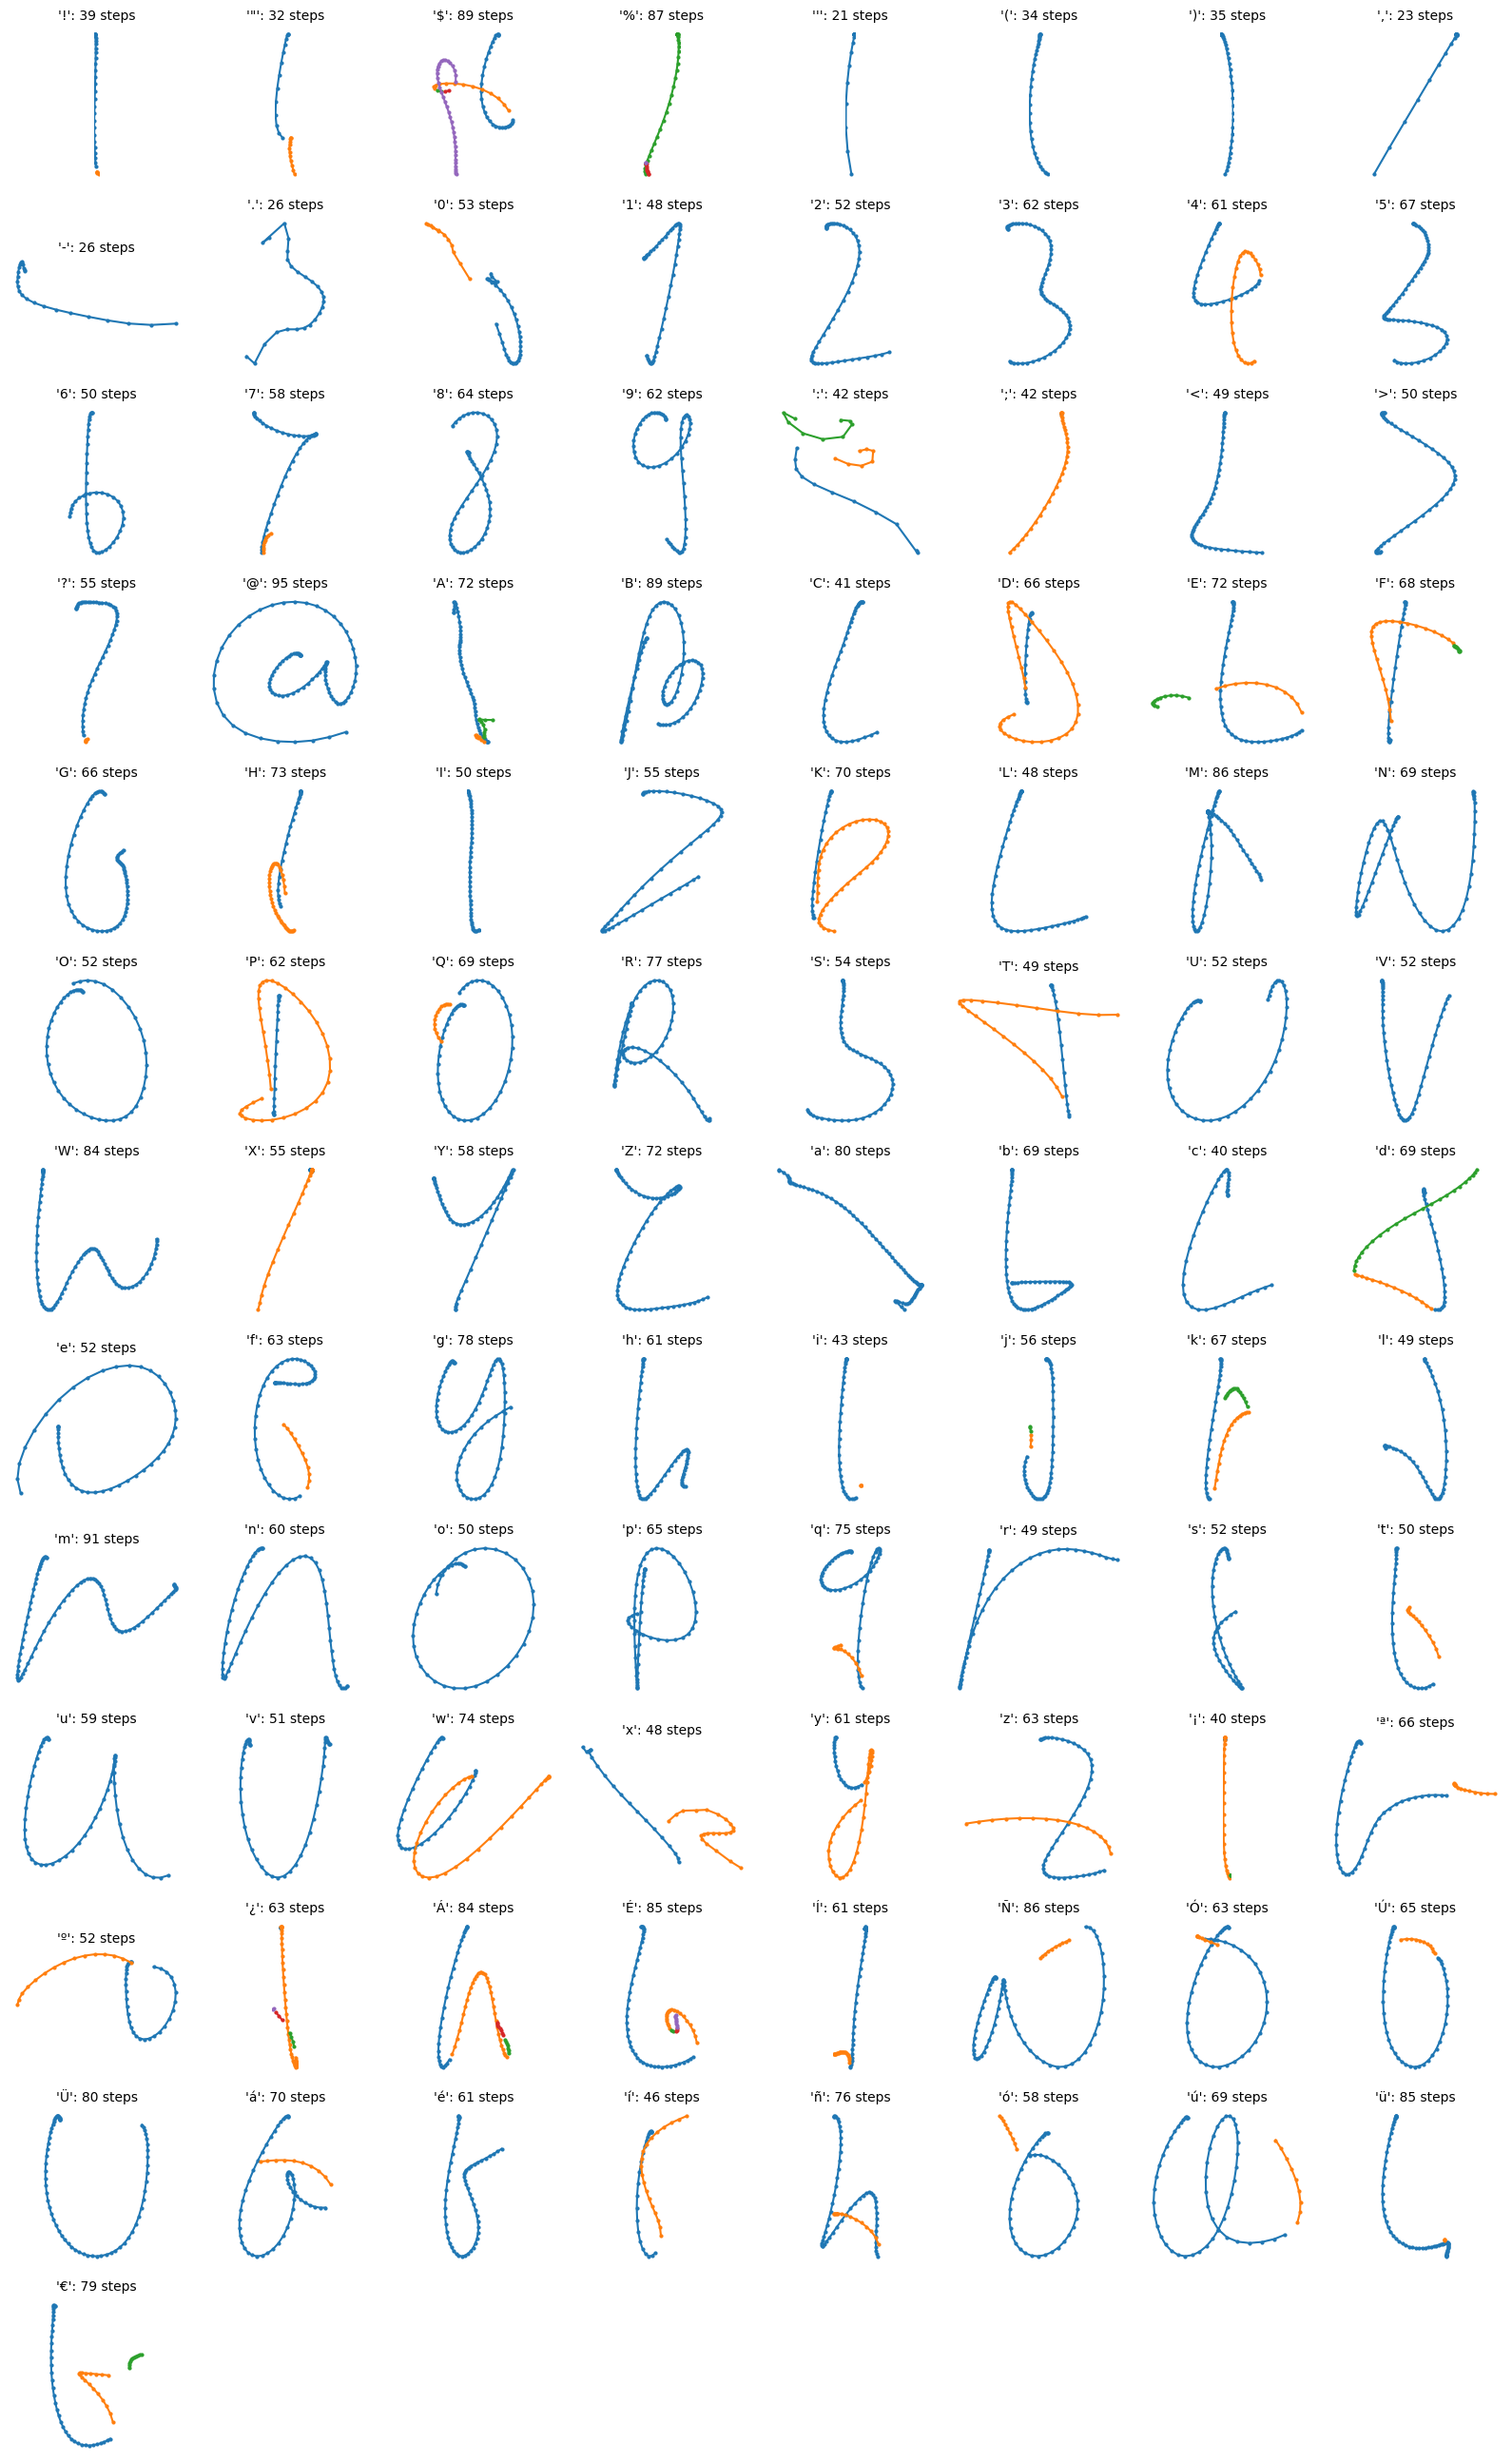

In [89]:
import math
import matplotlib.pyplot as plt

# Get all unique characters sorted
characters = sorted(char_to_id.keys())
ncols = 8
nrows = math.ceil(len(characters) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(2 * ncols, 2 * nrows))

for i, char in enumerate(characters):
    row = i // ncols
    col = i % ncols
    ax = axes[row, col]

    # Generate full trajectory using the trained model
    char_id = char_to_id[char]
    trajectory = generate_trajectory(model, char_id, max_steps=500)

    # Convert trajectory to drawable strokes
    strokes = deltas_to_strokes(trajectory)
    for stroke in strokes:
        xs, ys = zip(*stroke)
        ax.plot(xs, ys, "-o", markersize=2)

    ax.set_title(f"'{char}': {len(trajectory)} steps", fontsize=10)
    ax.set_aspect("equal")
    ax.axis("off")

# Turn off unused subplots if any
for j in range(i + 1, nrows * ncols):
    fig.delaxes(axes.flat[j])

plt.tight_layout()
plt.show()

Successfully loaded best model weights from 'lstm_mdn_best.pth'.


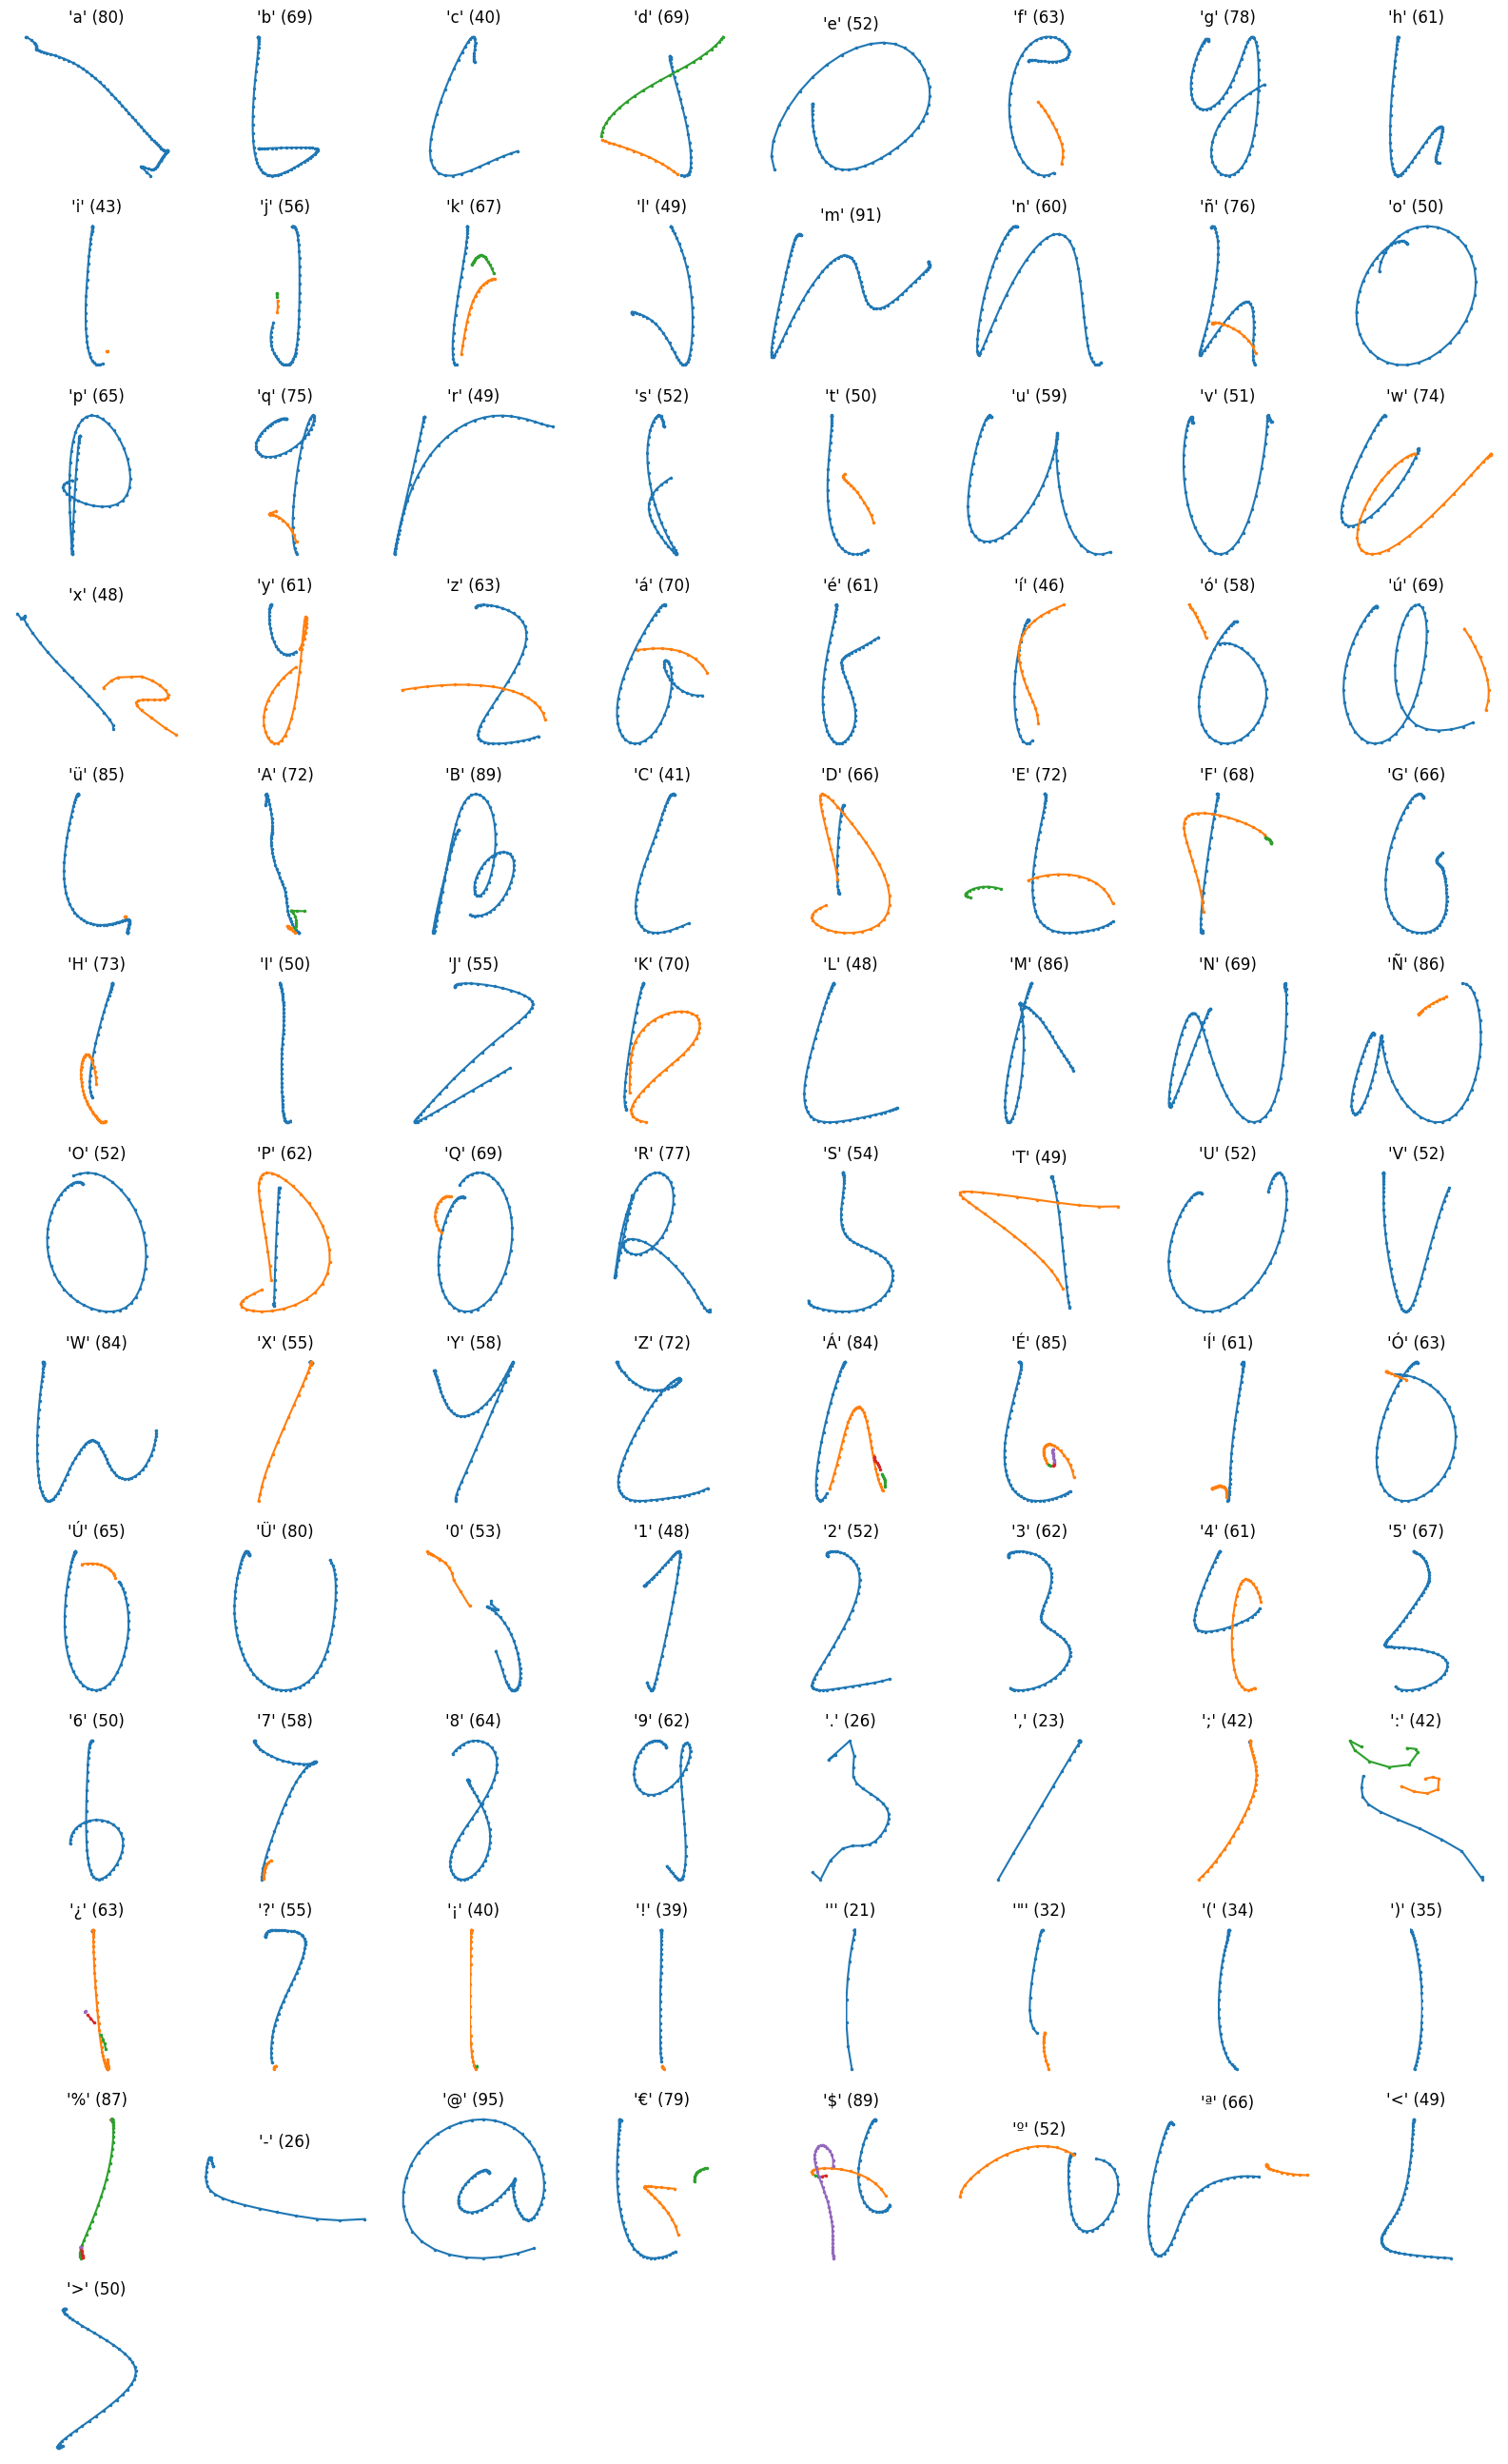

In [90]:
import torch
import math
import matplotlib.pyplot as plt

# 1. Initialize a new model instance with the same hyperparameters
eval_model = LSTMMDN(
    num_chars=num_chars,
    K=K,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    embedding_dim=EMBEDDING_DIM
).to(device)

# 2. Load the saved weights from the checkpoint file
checkpoint_path = "lstm_mdn_best.pth"
eval_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
eval_model.eval()
print(f"Successfully loaded best model weights from '{checkpoint_path}'.")

# 3. Generate trajectories using the loaded checkpoint
ncols = 8
nrows = math.ceil(num_chars / ncols)

plt.figure(figsize=(2 * ncols, 2 * nrows))

for i, ch in enumerate(all_chars):
    char_id = char_to_id[ch]
    # Generate full trajectory
    traj = generate_trajectory(eval_model, char_id, max_steps=max_len)

    plt.subplot(nrows, ncols, i + 1)
    plot_strokes(traj, f"'{ch}' ({len(traj)})")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Checks when something looks wrong

| symptom | what to look at |
|---|---|
| every character is flipped or shifted | the start token and the data orientation (must match training) |
| dots and crossbars are missing | raise `pen_up_boost` (try 5 to 20), or compare the number of pen-up steps with a real sample |
| characters stop too early | check how often the model predicts class 2, and the class weights |
| right shape but wrong size or drift at the end | error accumulates through the sum of deltas, try the sampled version with $\tau \approx 0.5$ to $0.8$ |
| two characters look alike | check the character-ID mapping and learned embeddings; compare settings of `EMBEDDING_DIM` |
| validation loss goes up while train loss goes down | overfitting, stop earlier or add dropout |